In [2]:
pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.4/75.4 kB 3.8 MB/s eta 0:00:00


### Utilize Nvidia **GPU**

In [1]:
!nvidia-smi

Thu Sep 10 08:06:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Loading **Dataset** **bold text**

In [3]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="sw4qEJVULbJ77VNSAXor")
project = rf.workspace("duong29").project("forest-lfqev")
version = project.version(3)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.8/302.8 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 95.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.4 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to forest-3 in yolov8:: 100%|██████████| 972/972 [00:03<00:00, 290.46it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.


### **Fine-Tuning YOLOv8-Seg**

In [5]:
from ultralytics import YOLO

# Initialize the YOLOv8 instance segmentation base model
model = YOLO('yolov8m-seg.pt')

# Train on the T4 GPU allocated in your Colab session
results = model.train(
    data='/content/forest-3/data.yaml',
    epochs=100,
    imgsz=1024,   # High resolution is critical for exact pixel boundaries
    batch=8,      # Reduced batch size because segmentation masks consume more VRAM
    device=0,
    project='Agroforestry',
    name='Canopy_Segmentation_V1'
)

Ultralytics 8.4.146 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/forest-3/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Canopy_Segmentation_V1-2, nbs=64, nms=None,

### **Inference & Spatial Surface Area Calculation**


image 1/1 /content/tree1.jpg: 1024x576 2 trees, 63.2ms
Speed: 3.0ms preprocess, 63.2ms inference, 1.9ms postprocess per image at shape (1, 3, 1024, 576)
--- Canopy Segmentation Visualization ---


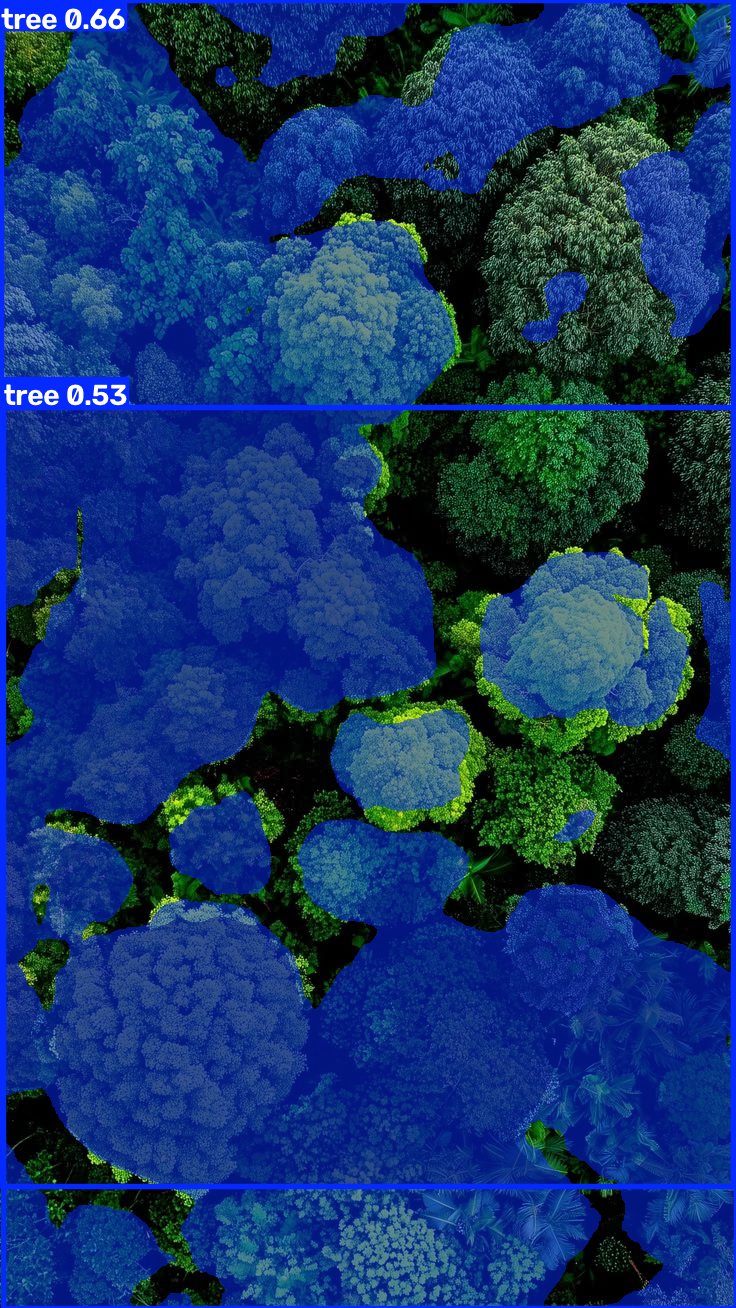


--- Surface Area Calculations ---
Tree 1 Canopy Area: 66.82 square meters
Tree 2 Canopy Area: 63.49 square meters


In [7]:
import numpy as np
import cv2
from ultralytics import YOLO
from google.colab.patches import cv2_imshow # Colab-safe image viewer

# Load your custom segmentation weights
best_seg_model = YOLO('/content/runs/segment/Agroforestry/Canopy_Segmentation_V1-2/weights/best.pt')

# Run inference on your high-res drone imagery
results = best_seg_model.predict(source='/content/tree1.jpg', conf=0.5)

# Define Ground Sampling Distance in meters (e.g., 1.5 cm = 0.015 m)
gsd_m = 0.015
pixel_area_sqm = gsd_m ** 2

for result in results:

    # 1. Visualize the Detection Inline
    # result.plot() generates a NumPy array of the image with all polygon masks drawn on it
    annotated_frame = result.plot()

    print("--- Canopy Segmentation Visualization ---")
    # Display the annotated image inline in your Colab notebook
    cv2_imshow(annotated_frame)
    print("\n--- Surface Area Calculations ---")

    # 2. Process Spatial Math
    # Ensure the model actually detected masks in the image
    if result.masks is not None:

        # Loop through each individually detected tree canopy mask
        for i, mask in enumerate(result.masks.data):

            # Convert the PyTorch tensor mask to a NumPy array for calculation
            mask_array = mask.cpu().numpy()

            # Count the total number of active canopy pixels (where value is 1.0)
            pixel_count = np.sum(mask_array == 1.0)

            # Calculate the exact physical surface area of the canopy
            canopy_area = pixel_count * pixel_area_sqm

            print(f"Tree {i+1} Canopy Area: {canopy_area:.2f} square meters")